# Activité 3 — RAG multimodal et agentique

Application interactive dans Jupyter. Le PDF source est la [version 7 de *Attention Is All You Need*](https://arxiv.org/abs/1706.03762v7). Ce projet reprend le principe du notebook de cours et sépare la recherche de la génération.

**Installation dans le dossier du projet** : `uv venv --python 3.11`, puis `uv pip install -r requirements.txt`. Dans VS Code, ouvrir ce dossier et sélectionner `.venv/bin/python` comme noyau. Le premier lancement télécharge l’article et les poids CLIP. Les données et l’index restent dans `.rag/`.

**Agent local** : démarrer Ollama puis lancer `ollama pull qwen3-vl:2b` pour analyser les pixels des figures, ou `ollama pull llama3.2:3b` pour une variante qui reçoit les passages et les légendes. Activer la cellule d’agent avec `EXECUTER_AGENT = True` après le démarrage d’Ollama.

## 1. Extraction multimodale

Le texte intégral est conservé par page. Les images intégrées sont rendues à leurs coordonnées dans le PDF. Pour la version 7 de l’article, trois captures recadrées incluent aussi les figures vectorielles 3 à 5 de l’appendice. Les coordonnées de l’appendice sont propres à cette version.

In [17]:
import os
from pathlib import Path
from urllib.request import urlretrieve

from IPython.display import display
from rag_pdf import PDF_URL, IndexPDF, extraire, sha256

cache = Path(os.environ.get("RAG_CACHE", ".rag"))
cache.mkdir(parents=True, exist_ok=True)
pdf = Path(os.environ.get("RAG_PDF", str(cache / "attention_is_all_you_need.pdf")))
if not pdf.is_file():
    if "RAG_PDF" in os.environ:
        raise FileNotFoundError(pdf)
    temporaire = pdf.with_suffix(".download")
    urlretrieve(PDF_URL, temporaire)
    temporaire.replace(pdf)

document = sha256(pdf)
canonique = "RAG_PDF" not in os.environ or os.environ.get("RAG_PDF_V7") == "1"
pages, visuels = extraire(pdf, cache / "extraits" / document, figures_appendice=canonique)
print(f"{len(pages)} pages de texte, {len(visuels)} visuels")
print("Identifiant SHA-256 :", document)


15 pages de texte, 6 visuels
Identifiant SHA-256 : bdfaa68d8984f0dc02beaca527b76f207d99b666d31d1da728ee0728182df697


## 2–3. Embeddings CLIP et index SQLite avec sqlite-vec

Le texte est découpé avec chevauchement selon les tokens du modèle, et les images sont encodées depuis leurs pixels. Les deux encodeurs renvoient des vecteurs L2 normalisés. Dans cet espace, le produit scalaire de deux vecteurs unitaires correspond à la similarité cosinus. Le cache dépend du contenu du PDF, de la configuration d’extraction et des poids CLIP. Les métadonnées conservent notamment la page, le type et le chemin relatif de l’image.

In [18]:
poids = os.environ.get("RAG_CLIP_POIDS", "openai")
index = IndexPDF(pdf, cache=cache, poids=poids, figures_appendice=canonique)
print("Contenu de l’index :", index.effectifs())
print("Dimension CLIP :", index.dimension)
print("Index réutilisé :", index.reutilise)


Contenu de l’index : {'texte': 200, 'image': 6}
Dimension CLIP : 512
Index réutilisé : True


## 4. Recherche et aperçu des résultats

Les trois cas ci-dessous couvrent la recherche par texte, par image et par fusion des deux. Les scores mesurent une proximité. Dans le cas mixte, le score est la moyenne des deux similarités cosinus.

Texte → texte
S0042 | p. 4 | texte | 0.853
) √ dk the two most commonly used attention functions are additive attention [ 2 ], and dot - produc
S0130 | p. 9 | texte | 0.838
the dropout , both attention and residual ( section 5 . 4 ), learning rates and beam size on the sec
S0047 | p. 4 | texte | 0.834
then perform the attention function in parallel , yielding dv - dimensional 4 to illustrate why the 

Texte → images
S0203 | p. 4 | image | 0.293
Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several atte


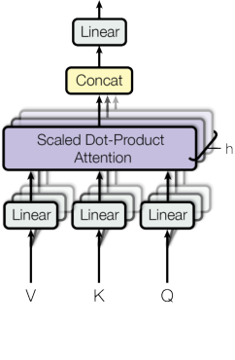

S0201 | p. 3 | image | 0.272
Figure 1: The Transformer - model architecture.


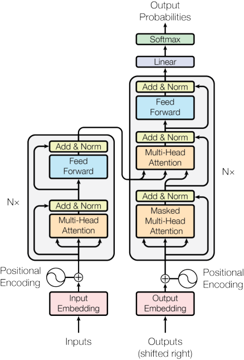

In [19]:
def apercu(resultats, images=True):
    for source in resultats:
        print(f"{source['id']} | p. {source['page']} | {source['type']} | {source['score']:.3f}")
        if source['texte']:
            print(source['texte'][:100])
        if images and source['type'] == "image":
            illustration = index.donner_image(source)
            illustration.thumbnail((360, 360))
            display(illustration)

print("Texte → texte")
apercu(index.chercher(texte="scaled dot product attention sqrt key dimension", k=3, cible="texte"))
print("\nTexte → images")
apercu(index.chercher(texte="Transformer encoder decoder architecture diagram", k=2, cible="image"))


In [20]:
figure = next(source for source in index.sources if source["type"] == "image")
image_exemple = index.donner_image(figure)
print("Image → images (test de cohérence, la figure est déjà indexée)")
similaires = index.chercher(image=image_exemple, k=2, cible="image")
assert similaires[0]["id"] == figure["id"]
apercu(similaires, images=False)

print("\nTexte + image → textes et images")
apercu(index.chercher(texte="Transformer encoder decoder", image=image_exemple, k=4), images=False)

# Pour une image externe : Image.open("mon_image.png").convert("RGB")


Image → images (test de cohérence, la figure est déjà indexée)
S0201 | p. 3 | image | 1.000
Figure 1: The Transformer - model architecture.
S0202 | p. 4 | image | 0.799
Figure 2: (left) Scaled Dot-Product Attention. (right) Multi-Head Attention consists of several atte

Texte + image → textes et images
S0201 | p. 3 | image | 0.625
Figure 1: The Transformer - model architecture.
S0031 | p. 3 | texte | 0.566
. 1 encoder and decoder stacks encoder : the encoder is composed of a stack of n = 6 identical layer
S0035 | p. 3 | texte | 0.564
, which performs multi - head attention over the output of the encoder stack . similar to the encode
S0056 | p. 5 | texte | 0.557
can attend to all positions in the previous layer of the encoder . • similarly , self - attention la


## 5–6. Outil et graphe ReAct

Le nœud **MIND** reçoit la question et décide s’il faut appeler `retriever_tool`. Le nœud **BODY** exécute la recherche et remet les sources brutes au modèle. Le retour au MIND permet une deuxième recherche ou une réponse finale. Le budget de trois appels est appliqué par le code. Avec un modèle vision, les pixels des figures récupérées sont ajoutés au contexte. Avec un modèle texte, la recherche utilise toujours les embeddings d’image, et la réponse s’appuie sur les passages et légendes disponibles.

In [21]:
from langchain_ollama import ChatOllama
from rag_pdf import construire_agent, interroger

EXECUTER_AGENT = True

def creer_agent(image=None):
    nom = os.environ.get("RAG_LLM", "llama3.2:3b")
    modele = ChatOllama(
        model=nom, temperature=0, reasoning=False, num_predict=256,
client_kwargs={"timeout": 120},
        base_url=os.environ.get("RAG_OLLAMA_URL", "http://127.0.0.1:11434"),
    )
    vision = os.environ.get("RAG_VISION", "1" if nom.startswith("qwen3-vl") else "0") == "1"
    return construire_agent(index, modele, image_jointe=image, vision=vision)

graphe, retriever_tool = creer_agent()
print("Outil :", retriever_tool.name)
print("Nœuds :", ", ".join(graphe.get_graph().nodes))


Outil : retriever_tool
Nœuds : __start__, mind, body, __end__


## 7. Validation et trace observable

Pour chaque question, relever les arguments des appels, les pages retournées et les citations dans la réponse. Une recherche conjointe doit chercher les passages et les figures. Si la question contient une image, vérifier que le mode demandé est `image` ou `mixte`. Pour une information absente, la réponse doit exprimer cette limite. Le test ci-dessus avec une image connue vérifie le câblage, et une image externe permet de tester une requête nouvelle.

In [22]:
from langchain_core.messages import AIMessage, ToolMessage

class ModeleDeTest:
    # Double de test : impose les décisions pour valider le graphe avec le vrai index.
    def bind_tools(self, outils):
        assert outils[0].name == "retriever_tool"
        return self

    def invoke(self, messages):
        nombre = sum(isinstance(message, ToolMessage) for message in messages)
        if nombre == 2:
            return AIMessage(content="Deux observations reçues. Fin du test de routage.")
        cible = ("image", "texte")[nombre]
        return AIMessage(content="", tool_calls=[{
            "name": "retriever_tool",
            "args": {"requete": "Transformer encoder decoder architecture", "mode": "mixte",
                     "cible": cible, "k": 2},
            "id": f"test-{nombre}",
        }])

test_graphe, _ = construire_agent(index, ModeleDeTest(), image_jointe=image_exemple)
controle = interroger(test_graphe, "Retrouve la figure et les passages qui l’expliquent.")
assert len(controle["actions"]) == len(controle["observations"]) == 2
for cible, observation in zip(("image", "texte"), controle["observations"]):
    assert observation["sources"] and all(s["type"] == cible for s in observation["sources"])
    print(cible, "→", [(s["id"], s["page"]) for s in observation["sources"]])
print(controle["reponse"])


image → [('S0201', 3), ('S0203', 4)]
texte → [('S0031', 3), ('S0035', 3)]
Deux observations reçues. Fin du test de routage.


In [26]:
def afficher_trace(sortie):
    for appel in sortie["actions"]:
        print("Action :", appel["name"], appel["args"])
    for observation in sortie["observations"]:
        sources = observation["sources"]
        if isinstance(sources, list):
            print("Observation :", [(s["id"], s["page"], s["type"]) for s in sources])
        else:
            print("Observation :", sources)
    print("Réponse :", sortie["reponse"])

if EXECUTER_AGENT:
    scenarios = [
        ("Compare la figure de l’architecture et le texte sur les différences entre encodeur et décodeur.", None),
                ("Utilise retriever_tool en mode mixte, cible tous, k=4, avec la requête Transformer encoder decoder architecture. Identifie la figure et explique la différence entre l’encodeur et le décodeur. Cite tes sources.", image_exemple),
        ("Quel est le résultat du Transformer sur MNIST dans cet article ?", None),
    ]
    for question, image in scenarios[1:2]:
        print("\nQuestion :", question)
        agent, _ = creer_agent(image)
        afficher_trace(interroger(agent, question))
else:
    print("Agent configuré. Active EXECUTER_AGENT après avoir démarré Ollama.")



Question : Utilise retriever_tool en mode mixte, cible tous, k=4, avec la requête Transformer encoder decoder architecture. Identifie la figure et explique la différence entre l’encodeur et le décodeur. Cite tes sources.
Action : retriever_tool {'cible': 'tous', 'k': '4', 'mode': 'mixte', 'requete': 'Transformer encoder decoder architecture'}
Observation : [('S0201', 3, 'image'), ('S0031', 3, 'texte'), ('S0035', 3, 'texte'), ('S0139', 10, 'texte')]
Réponse : La figure identifiée est la figure 1 : "The Transformer - model architecture" (S0201, p. 3).

La différence entre l'encodeur et le décodeur dans l'architecture Transformer est la suivante :

L'encodeur est composé de plusieurs couches identiques, chacune contenant deux sous-couches :

1. Une couche de multi-head attention
2. Une couche de réseau de feed-forward simple et position-wise

L'encodeur est également équipé de connections de résiduel et de normalisation de couches.

Le décodeur est similaire à l'encodeur, mais avec une m